In [1]:
import os
print(os.getcwd())

c:\Users\somus\Desktop\CarPredic\notebooks


In [ ]:
import sys
sys.path.append('../src')

import importlib
import load_data
importlib.reload(load_data)
import numpy as np
import pandas as pd
from load_data import load_and_clean_data, stratified_split
from pipeline import build_pipeline

df = load_data.load_and_clean_data()
train_set, test_set = stratified_split(df)

car = train_set.drop('Price', axis=1) #input feature's
car_labels = train_set['Price'].copy() #output feature's

full_pipeline = build_pipeline()
car_prepared = full_pipeline.fit_transform(car)
car_prepared.shape

(1646, 1063)

In [9]:
train_set.to_csv("../data/processed/train.csv", index=False)
test_set.to_csv("../data/processed/test.csv", index=False)

In [10]:
from sklearn.linear_model import LinearRegression

lin_reg = LinearRegression()
lin_reg.fit(car_prepared, car_labels)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1063,)","[ 525912.84, -36672.52,-1918841.96,..., -194034.6 , 1160971.34, -966936.74]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,3.321e+06
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1063


In [11]:
from sklearn.ensemble import RandomForestRegressor

forest_reg = RandomForestRegressor(random_state=42)
forest_reg.fit(car_prepared, car_labels)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease o

In [12]:
from sklearn.model_selection import cross_val_score

def display_scores(scores, name):
    print(f"{name}")
    print("Scores:", scores)
    print("Mean:", scores.mean())
    print("Std:", scores.std())
    print()

lin_scores = cross_val_score(lin_reg, car_prepared, car_labels,
                              scoring="neg_mean_squared_error", cv=10)
forest_scores = cross_val_score(forest_reg, car_prepared, car_labels,
                                 scoring="neg_mean_squared_error", cv=10)

display_scores(np.sqrt(-lin_scores), "Linear Regression")
display_scores(np.sqrt(-forest_scores), "Random Forest")

Linear Regression
Scores: [2467322.70987121 2591608.77254443 2703391.79452034 4391555.05608313
 2204323.79697685 2258282.04374002 1617010.21224619 2700856.98997616
 3664170.41476258 1054048.92537351]
Mean: 2565257.0716094417
Std: 894324.1928268067

Random Forest
Scores: [ 631094.14112674 1089444.83117806  512160.33388321 1350071.26402094
  555537.93783663  764158.48947494  847377.88808202  936382.41292841
 1792887.7594257   486075.74989254]
Mean: 896519.080784918
Std: 396338.7335305077



In [13]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

results = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "RMSE": [
        np.sqrt(mean_squared_error(car_labels, lin_reg.predict(car_prepared))),
        np.sqrt(mean_squared_error(car_labels, forest_reg.predict(car_prepared)))
    ],
    "MAE": [
        mean_absolute_error(car_labels, lin_reg.predict(car_prepared)),
        mean_absolute_error(car_labels, forest_reg.predict(car_prepared))
    ],
    "R2 Score": [
        r2_score(car_labels, lin_reg.predict(car_prepared)),
        r2_score(car_labels, forest_reg.predict(car_prepared))
    ]
})

print(results)

               Model           RMSE            MAE  R2 Score
0  Linear Regression  242843.574042  115816.038802  0.990449
1      Random Forest  379701.145764  113852.676328  0.976650


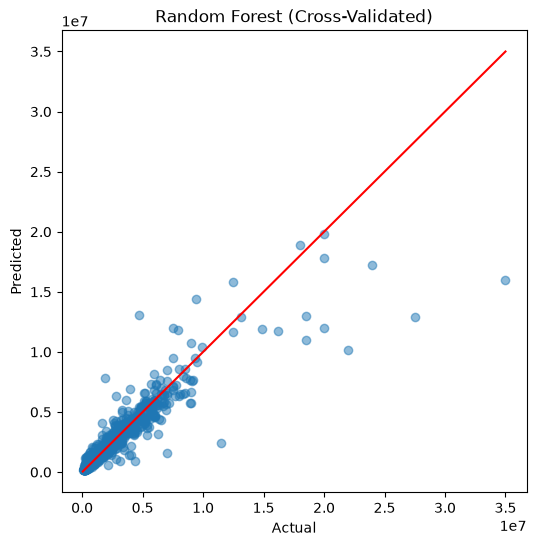

In [14]:
from sklearn.model_selection import cross_val_predict

rf_preds = cross_val_predict(forest_reg, car_prepared, car_labels, cv=10)
lin_preds = cross_val_predict(lin_reg, car_prepared, car_labels, cv=10)

import matplotlib.pyplot as plt

plt.figure(figsize=(6,6))
plt.scatter(car_labels, rf_preds, alpha=0.5)
plt.plot([car_labels.min(), car_labels.max()],
         [car_labels.min(), car_labels.max()],
         color='red')
plt.title("Random Forest (Cross-Validated)")
plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.show()

In [16]:
import joblib
import os

os.makedirs("../models", exist_ok=True)

joblib.dump(forest_reg, "../models/forest_model.pkl")
joblib.dump(full_pipeline, "../models/pipeline.pkl")

['../models/pipeline.pkl']